# Natural Scene Image Classification — CNN Training Notebook

Trains and evaluates a CNN on the Intel Image Classification dataset
(6 scene classes: buildings, forest, glacier, mountain, sea, street).

Covers: dataset overview, preprocessing, CNN architecture, training with
EarlyStopping, evaluation (accuracy/precision/recall/F1/confusion matrix),
training curves, and two hyperparameter tuning experiments.

In [ ]:
# Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix

## Configuration
All tunable settings live here — edit these instead of searching through the code below.

In [ ]:
class Config:
    # --- Paths ---
    TRAIN_DIR = "/content/mid/archive/seg_train"
    TEST_DIR  = "/content/mid/archive/seg_test"
    OUTPUT_DIR = "outputs"

    # --- Data ---
    IMG_SIZE = (150, 150)
    BATCH_SIZE = 32
    VALIDATION_SPLIT = 0.2
    CLASS_NAMES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
    SEED = 42

    # --- Model architecture ---
    BASE_FILTERS = 32       # Conv Block 1 filter count; blocks 2/3 scale x2, x4
    DROPOUT_RATE = 0.5
    DENSE_UNITS = 128

    # --- Training ---
    LEARNING_RATE = 1e-3
    EPOCHS = 30
    EARLY_STOPPING_PATIENCE = 5

    # --- Tuning experiments  ---
    TUNING_EXPERIMENTS = [
        {"label": "LR=1e-4", "lr": 1e-4, "dropout_rate": 0.5, "epochs": 15},
        {"label": "Dropout=0.3", "lr": 1e-3, "dropout_rate": 0.3, "epochs": 15},
    ]


# Reproducibility: fix seeds so runs are comparable across experiments
tf.random.set_seed(Config.SEED)
np.random.seed(Config.SEED)
os.makedirs(Config.OUTPUT_DIR, exist_ok=True)

## 1. Dataset Overview (Section 2)
Count images per class and visualize class balance.

In [ ]:
def count_images_per_class(directory: str) -> dict:
    """
    Count the number of image files in each class subfolder.



    Args:
        directory: path to a folder containing one subfolder per class.

    Returns:
        dict mapping class name -> image count.
    """
    counts = {}
    for cls in sorted(os.listdir(directory)):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts


def plot_class_distribution(train_counts: dict, test_counts: dict) -> None:
    """Bar chart comparing per-class image counts across train/test splits."""
    df_counts = pd.DataFrame({"Train": train_counts, "Test": test_counts})
    print(df_counts)

    df_counts.plot(kind="bar", figsize=(8, 5))
    plt.title("Number of Images per Class")
    plt.ylabel("Image Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(Config.OUTPUT_DIR, "class_distribution.png"), dpi=150)
    plt.show()

           Train  Test
buildings   2191   437
forest      2271   474
glacier     2404   553
mountain    2512   525
sea         2274   510
street      2382   501


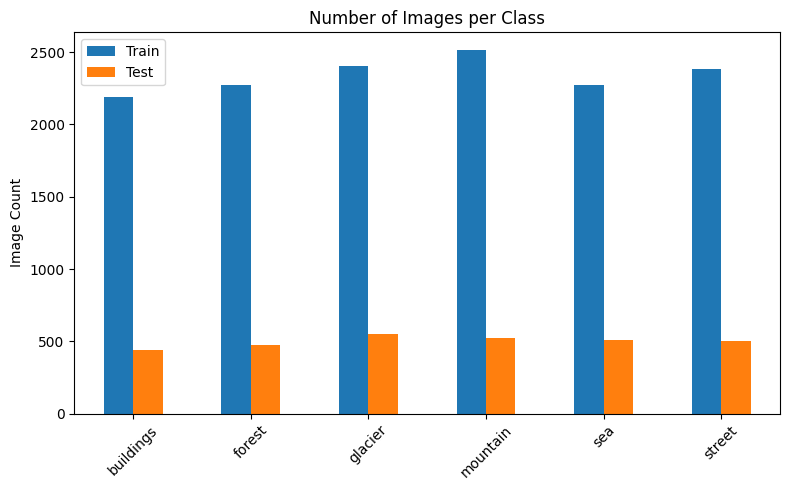

In [ ]:
train_counts = count_images_per_class(Config.TRAIN_DIR)
test_counts = count_images_per_class(Config.TEST_DIR)
plot_class_distribution(train_counts, test_counts)

## 2. Data Loading & Preprocessing (Section 3)
Load images from disk, split train/validation, normalize pixels, and build an efficient `tf.data` pipeline.

In [ ]:
def load_datasets():
    """
    Build train/validation/test tf.data pipelines from the directory structure.

    - Labels are inferred from subfolder names (label_mode="int" -> integer
      labels, paired with sparse_categorical_crossentropy later).
    - Train/validation come from the same TRAIN_DIR via validation_split,
      using a fixed seed so the split is reproducible.
    - Test set is NOT shuffled, so predictions line up with true labels
      for the confusion matrix / classification report.

    Returns:
        (train_ds, val_ds, test_ds) as tf.data.Dataset objects (raw, 0-255 pixels).
    """
    common_kwargs = dict(
        labels="inferred",
        label_mode="int",
        class_names=Config.CLASS_NAMES,
        color_mode="rgb",
        image_size=Config.IMG_SIZE,
        batch_size=Config.BATCH_SIZE,
    )

    train_ds = tf.keras.utils.image_dataset_from_directory(
        Config.TRAIN_DIR, shuffle=True, seed=Config.SEED,
        validation_split=Config.VALIDATION_SPLIT, subset="training",
        **common_kwargs,
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        Config.TRAIN_DIR, shuffle=True, seed=Config.SEED,
        validation_split=Config.VALIDATION_SPLIT, subset="validation",
        **common_kwargs,
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        Config.TEST_DIR, shuffle=False, **common_kwargs,
    )

    return train_ds, val_ds, test_ds


def preprocess(ds: tf.data.Dataset, training: bool = False) -> tf.data.Dataset:
    """
    Apply pixel normalization and an efficient tf.data pipeline.

    - Rescaling(1/255): normalizes pixels from [0, 255] to [0, 1], which
      keeps gradients well-scaled and speeds up convergence.
    - shuffle(): only applied to training data, to avoid learning order
      artifacts across epochs.
    - cache(): keeps decoded images in memory/disk after the first epoch,
      avoiding repeated JPEG decoding -- a major speedup on limited hardware.
    - prefetch(AUTOTUNE): overlaps data loading with model execution on the
      GPU/CPU, so the training step doesn't stall waiting for the next batch.

    Args:
        ds: raw tf.data.Dataset with pixel values in [0, 255].
        training: whether to shuffle (True for the training set only).

    Returns:
        A preprocessed, performance-optimized tf.data.Dataset.
    """
    normalization_layer = layers.Rescaling(1.0 / 255)
    ds = ds.map(lambda x, y: (normalization_layer(x), y),
                num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(1000)
    return ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [ ]:
train_ds, val_ds, test_ds = load_datasets()
train_ds_prepped = preprocess(train_ds, training=True)
val_ds_prepped = preprocess(val_ds)
test_ds_prepped = preprocess(test_ds)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


## 3. Model Architecture (Section 5)

In [ ]:
def build_cnn(input_shape=(150, 150, 3), num_classes=6,
              base_filters=Config.BASE_FILTERS,
              dropout_rate=Config.DROPOUT_RATE,
              dense_units=Config.DENSE_UNITS) -> tf.keras.Model:
    """
    Build the CNN classifier architecture.

    Architecture rationale:
        - 3 Conv blocks (filters double each block): each block extracts
          progressively more abstract spatial features -- edges/textures in
          early layers, scene-level structures in deeper layers.
        - BatchNormalization after each conv layer: stabilizes and speeds
          up training by normalizing intermediate activations, reducing
          sensitivity to weight initialization and learning rate.
        - MaxPooling2D after each block: reduces spatial dimensions (and
          therefore parameter count / compute), and adds a degree of
          translation invariance.
        - Flatten + Dense(dense_units): learns non-linear combinations of
          the extracted convolutional features.
        - Dropout: randomly deactivates neurons during training so the
          network can't over-rely on specific feature co-occurrences --
          the main defense against overfitting in this architecture.
        - Final Dense(num_classes, softmax): outputs a probability
          distribution over the 6 mutually exclusive scene classes.

    Args:
        input_shape: shape of input images (H, W, channels).
        num_classes: number of output classes.
        base_filters: filter count for the first conv block (doubles per block).
        dropout_rate: dropout probability applied before the output layer.
        dense_units: number of units in the fully connected hidden layer.

    Returns:
        An uncompiled tf.keras.Model.
    """
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Conv Block 1
        layers.Conv2D(base_filters, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 2
        layers.Conv2D(base_filters * 2, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 3
        layers.Conv2D(base_filters * 4, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Classifier head
        layers.Flatten(),
        layers.Dense(dense_units, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(num_classes, activation="softmax"),
    ], name="intel_scene_cnn")

    return model


model = build_cnn()
model.summary()

Model: "intel_scene_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,403,462 (20.61 MB)

 Trainable params: 5,403,014 (20.61 MB)

 Non-trainable params: 448 (1.75 KB)

## 4. Loss Function & Optimizer (Section 6)

In [ ]:
def compile_model(model: tf.keras.Model, learning_rate: float) -> tf.keras.Model:
    """
    Compile with sparse categorical cross-entropy (integer labels, 6 classes)
    and Adam (adaptive per-parameter learning rates -- converges reliably on
    image data without heavy manual LR scheduling).
    """
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


compile_model(model, learning_rate=Config.LEARNING_RATE)

<Sequential name=intel_scene_cnn, built=True>

## 5. Training with EarlyStopping (Section 7)

In [ ]:
def train_model(model: tf.keras.Model, train_ds, val_ds,
                 epochs: int, patience: int, verbose: int = 1):
    """
    Fit the model with EarlyStopping on validation loss.

    EarlyStopping(restore_best_weights=True) both prevents wasted epochs
    once the model stops improving AND ensures the final weights are the
    best-performing ones seen during training, not just the last epoch's.
    """
    early_stop = callbacks.EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )
    history = model.fit(
        train_ds, validation_data=val_ds, epochs=epochs,
        callbacks=[early_stop], verbose=verbose,
    )
    return history


history = train_model(
    model, train_ds_prepped, val_ds_prepped,
    epochs=Config.EPOCHS, patience=Config.EARLY_STOPPING_PATIENCE,
)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 33s 52ms/step - accuracy: 0.3977 - loss: 2.1840 - val_accuracy: 0.3867 - val_loss: 1.8548
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.4641 - loss: 1.2803 - val_accuracy: 0.5078 - val_loss: 1.1189
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.5289 - loss: 1.1443 - val_accuracy: 0.5267 - val_loss: 1.0534
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.5508 - loss: 1.0817 - val_accuracy: 0.4989 - val_loss: 1.3370
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.5738 - loss: 1.0389 - val_accuracy: 0.6568 - val_loss: 0.9065
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.6155 - loss: 0.9377 - val_accuracy: 0.5260 - val_loss: 1.1740
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.6316 - loss: 0.8843 - val_accuracy: 0.6582 - val_loss: 1.0180
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.6495 - loss: 0.8472 - 

## 6. Training Curves

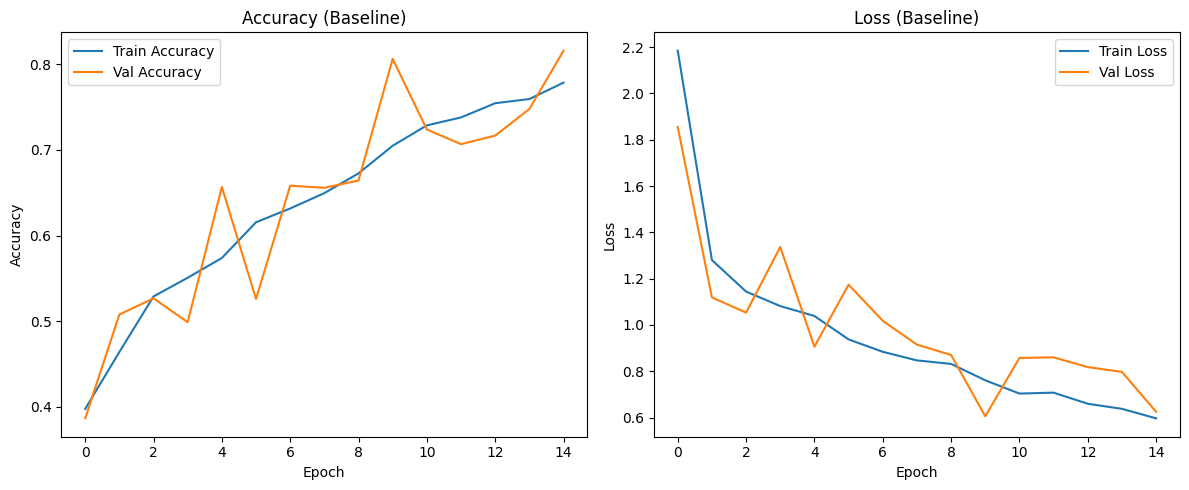

In [ ]:
def plot_history(history, title_suffix: str = "") -> None:
    """Plot and save training/validation accuracy and loss curves."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(history.history["accuracy"], label="Train Accuracy")
    axes[0].plot(history.history["val_accuracy"], label="Val Accuracy")
    axes[0].set_title(f"Accuracy {title_suffix}")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(history.history["loss"], label="Train Loss")
    axes[1].plot(history.history["val_loss"], label="Val Loss")
    axes[1].set_title(f"Loss {title_suffix}")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    fname = f"training_curves{title_suffix.replace(' ', '_')}.png"
    plt.savefig(os.path.join(Config.OUTPUT_DIR, fname), dpi=150)
    plt.show()


plot_history(history, "(Baseline)")

## 7. Evaluation: Accuracy, Precision, Recall, F1, Confusion Matrix (Section 8)

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.8130 - loss: 0.5749
Test Accuracy: 0.8130
Test Loss: 0.5749
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
              precision    recall  f1-score   support

   buildings     0.7788    0.8055    0.7919       437
      forest     0.9419    0.9578    0.9498       474
     glacier     0.8741    0.6528    0.7474       553
    mountain     0.6609    0.8762    0.7535       525
         sea     0.8221    0.8157    0.8189       510
      street     0.8780    0.7904    0.8319       501

    accuracy                         0.8130      3000
   macro avg     0.8260    0.8164    0.8156      3000
weighted avg     0.8254    0.8130    0.8132      3000



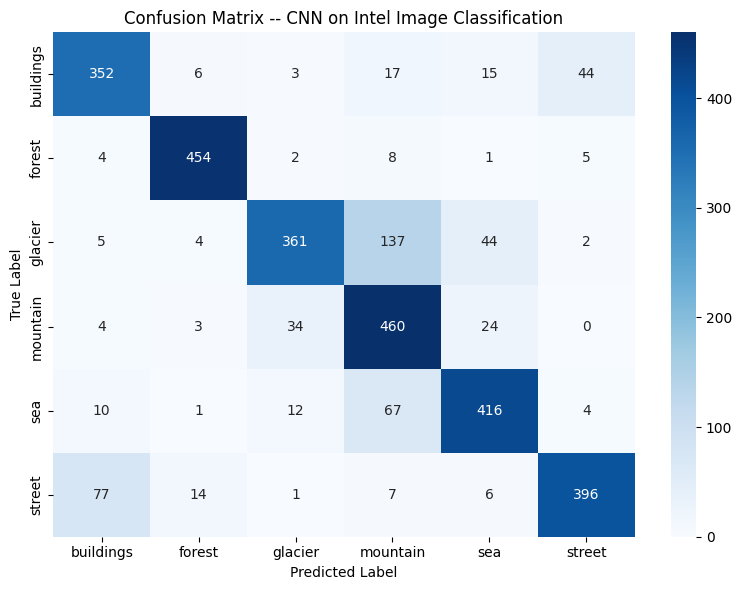

In [ ]:
def evaluate_model(model: tf.keras.Model, test_ds) -> tuple:
    """
    Evaluate on the held-out test set: overall accuracy/loss, per-class
    precision/recall/F1 (via classification_report), and a confusion matrix.

    Returns:
        (y_true, y_pred) arrays, for any further custom analysis.
    """
    test_loss, test_accuracy = model.evaluate(test_ds)
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Test Loss: {test_loss:.4f}")

    y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
    y_pred_probs = model.predict(test_ds)
    y_pred = np.argmax(y_pred_probs, axis=1)

    report = classification_report(
        y_true, y_pred, target_names=Config.CLASS_NAMES, digits=4
    )
    print(report)
    with open(os.path.join(Config.OUTPUT_DIR, "classification_report.txt"), "w") as f:
        f.write(report)

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=Config.CLASS_NAMES, yticklabels=Config.CLASS_NAMES)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix -- CNN on Intel Image Classification")
    plt.tight_layout()
    plt.savefig(os.path.join(Config.OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
    plt.show()

    return y_true, y_pred


y_true, y_pred = evaluate_model(model, test_ds_prepped)

## 8. Hyperparameter Tuning Experiments (Section 7)
Two experiments: a lower learning rate, and a lower dropout rate. Each trains a fresh model so results are independent.

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.5786 - loss: 1.2039 - val_accuracy: 0.3432 - val_loss: 3.3170
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.6935 - loss: 0.8511 - val_accuracy: 0.7202 - val_loss: 0.7652
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.7394 - loss: 0.7161 - val_accuracy: 0.7887 - val_loss: 0.6053
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.7848 - loss: 0.5870 - val_accuracy: 0.7776 - val_loss: 0.6747
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8140 - loss: 0.5057 - val_accuracy: 0.8015 - val_loss: 0.6254
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8390 - loss: 0.4416 - val_accuracy: 0.8072 - val_loss: 0.5744
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8600 - loss: 0.3759 - val_accuracy: 0.7733 - val_loss: 0.7519
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8784 - loss: 0.3222 - 

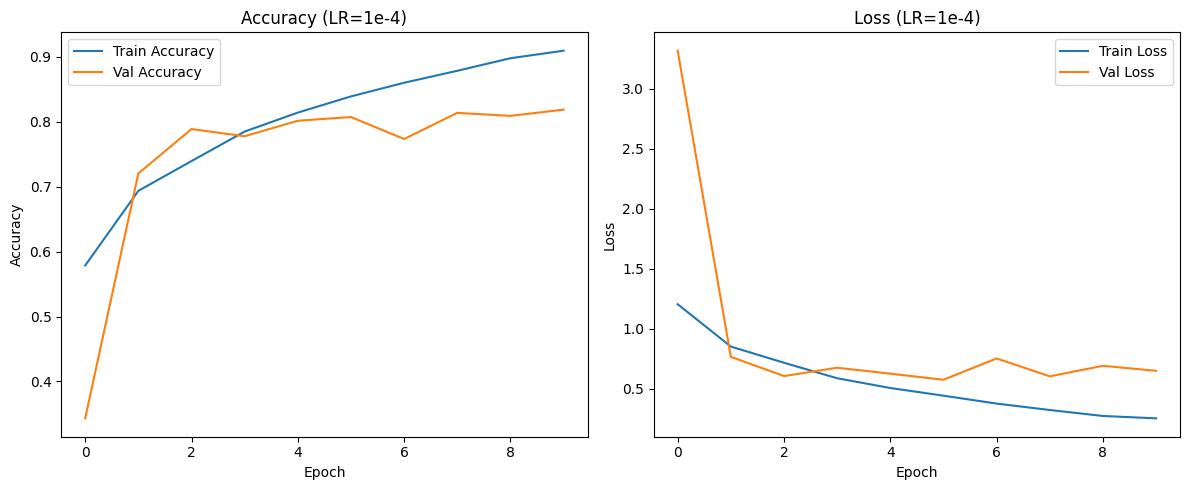

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 45ms/step - accuracy: 0.4910 - loss: 1.9884 - val_accuracy: 0.4751 - val_loss: 3.1760
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.6060 - loss: 1.0195 - val_accuracy: 0.7284 - val_loss: 0.7635
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.6564 - loss: 0.8908 - val_accuracy: 0.7292 - val_loss: 0.7626
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.6848 - loss: 0.8288 - val_accuracy: 0.5759 - val_loss: 1.1998
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.7227 - loss: 0.7369 - val_accuracy: 0.7302 - val_loss: 0.7420
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.7522 - loss: 0.6685 - val_accuracy: 0.7217 - val_loss: 0.7286
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.7618 - loss: 0.6503 - val_accuracy: 0.7872 - val_loss: 0.6316
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.7793 - loss: 0.5946 - 

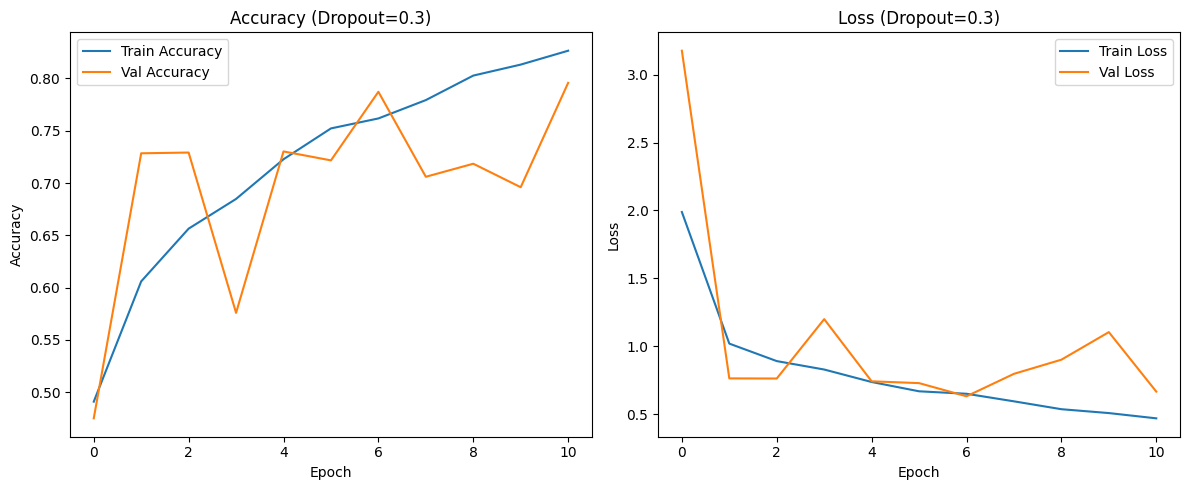

In [ ]:
def run_tuning_experiment(train_ds, val_ds, lr: float, dropout_rate: float,
                           epochs: int, label: str) -> dict:
    """
    Train one variant of the model for a hyperparameter-tuning comparison
     Builds a fresh model each time so experiments don't share
    weights/state.

    Returns:
        dict with the trained model, its History, and best validation accuracy.
    """
    exp_model = build_cnn(dropout_rate=dropout_rate)
    compile_model(exp_model, learning_rate=lr)
    exp_history = train_model(exp_model, train_ds, val_ds, epochs=epochs, patience=4)
    val_acc = max(exp_history.history["val_accuracy"])
    print(f"[{label}] Best Validation Accuracy: {val_acc:.4f}")
    plot_history(exp_history, f"({label})")
    return {"label": label, "model": exp_model, "history": exp_history, "val_acc": val_acc}


tuning_results = []
for exp in Config.TUNING_EXPERIMENTS:
    result = run_tuning_experiment(
        train_ds_prepped, val_ds_prepped,
        lr=exp["lr"], dropout_rate=exp["dropout_rate"],
        epochs=exp["epochs"], label=exp["label"],
    )
    tuning_results.append(result)

## 9. Tuning Summary Table

In [ ]:
summary_df = pd.DataFrame({
    "Experiment": ["Baseline"] + [r["label"] for r in tuning_results],
    "Best Val Accuracy": [max(history.history["val_accuracy"])]
                          + [r["val_acc"] for r in tuning_results],
})
print(summary_df)
summary_df.to_csv(os.path.join(Config.OUTPUT_DIR, "tuning_results.csv"), index=False)

    Experiment  Best Val Accuracy
0     Baseline           0.815752
1      LR=1e-4           0.818603
2  Dropout=0.3           0.795795


## 10. Save Final Model

In [ ]:
model.save(os.path.join(Config.OUTPUT_DIR, "intel_scene_cnn.keras"))
print(f"Model saved to {Config.OUTPUT_DIR}/intel_scene_cnn.keras")

Model saved to outputs/intel_scene_cnn.keras
